## 1. Dataset Import and Shape

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

recipes = pd.read_csv("RAW_recipes.csv")
interactions = pd.read_csv("RAW_interactions.csv")

print("Recipes:", recipes.shape)
print("Interactions:", interactions.shape)

display(recipes.head())
display(interactions.head())

Recipes: (231637, 12)
Interactions: (1132367, 5)


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


## 2. Machine Learning Problem Definition

**Goal:** Predict the rating (1 to 5) that a user would give a recipe they have not rated before.

This is a supervised **regression** problem because the target variable is the user's numerical recipe rating. Each observation represents one user-recipe interaction.

- **Target:** `rating`
- **Recipe information:** cooking time, number of steps, number of ingredients, and nutrition values.
- **User and interaction information:** user ID, recipe ID, and historical interaction patterns.
- **Evaluation:** Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). Lower values indicate better predictions.

The main challenge is sparsity: most users and recipes have very few ratings. The rating distribution is also imbalanced toward high ratings. Ratings of zero will be investigated separately because they may represent interactions without an actual submitted rating, rather than a normal one-star rating.

We will compare simple baselines, content-based models, and collaborative-filtering approaches. A random interaction split measures performance on unseen interactions, but it does not fully measure performance for entirely new users or recipes.

## 3. Initial Project Plan

1. **Exploratory data analysis:** Understand rating distributions, missing values, user activity, recipe popularity, and relationships between recipe features and ratings.
2. **Data preparation:** Merge interactions with recipe information, inspect zero ratings, parse nutrition values, select useful features, and create training and testing sets.
3. **Baseline models:** Establish simple reference performance using the global average and user/recipe averages.
4. **Machine learning models:** Train and compare regression models using recipe characteristics. Explore collaborative filtering.
5. **Evaluation:** Compare MAE and RMSE, inspect errors, and look for overfitting by comparing training and testing performance.
6. **Improvements:** Consider feature engineering, hyperparameter tuning, and hybrid approaches that combine recipe characteristics with user preferences.

The exact models and features may change based on the EDA and initial results.

## 4. Dataset Features and Data Types

In [2]:

print("RECIPE FEATURES")
print(recipes.info())

print("\nINTERACTION FEATURES")
print(interactions.info())

# Detailed feature overview
display(pd.DataFrame({
    "Feature": recipes.columns,
    "Data Type": recipes.dtypes.astype(str).values
}))

display(pd.DataFrame({
    "Feature": interactions.columns,
    "Data Type": interactions.dtypes.astype(str).values
}))


RECIPE FEATURES
<class 'pandas.DataFrame'>
RangeIndex: 231637 entries, 0 to 231636
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   name            231636 non-null  str  
 1   id              231637 non-null  int64
 2   minutes         231637 non-null  int64
 3   contributor_id  231637 non-null  int64
 4   submitted       231637 non-null  str  
 5   tags            231637 non-null  str  
 6   nutrition       231637 non-null  str  
 7   n_steps         231637 non-null  int64
 8   steps           231637 non-null  str  
 9   description     226658 non-null  str  
 10  ingredients     231637 non-null  str  
 11  n_ingredients   231637 non-null  int64
dtypes: int64(5), str(7)
memory usage: 293.5 MB
None

INTERACTION FEATURES
<class 'pandas.DataFrame'>
RangeIndex: 1132367 entries, 0 to 1132366
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id

,Feature,Data Type
0,name,str
1,id,int64
2,minutes,int64
3,contributor_id,int64
4,submitted,str
5,tags,str
6,nutrition,str
7,n_steps,int64
8,steps,str
9,description,str


,Feature,Data Type
0,user_id,int64
1,recipe_id,int64
2,date,str
3,rating,int64
4,review,str


## 5. Missing Value Analysis

In [3]:

recipe_missing = pd.DataFrame({
    "Missing Count": recipes.isnull().sum(),
})

interaction_missing = pd.DataFrame({
    "Missing Count": interactions.isnull().sum(),
})

print("Missing values in recipes:")
display(recipe_missing)

print("Missing values in interactions:")
display(interaction_missing)


Missing values in recipes:


,Missing Count
name,1
id,0
minutes,0
contributor_id,0
submitted,0
tags,0
nutrition,0
n_steps,0
steps,0
description,4979


Missing values in interactions:


,Missing Count
user_id,0
recipe_id,0
date,0
rating,0
review,169


## 6. Duplicate Record Analysis

In [4]:

print("Duplicate recipe rows:", recipes.duplicated().sum())

print("Duplicate recipe IDs:", recipes["id"].duplicated().sum())

print("Duplicate interaction rows:", interactions.duplicated().sum())

print("Repeated user-recipe pairs:",
      interactions.duplicated(
          subset=["user_id", "recipe_id"]
      ).sum())


Duplicate recipe rows: 0
Duplicate recipe IDs: 0
Duplicate interaction rows: 0
Repeated user-recipe pairs: 0


## 7. Rating Statistics and Distribution

Rating statistics:


count   1132367.00
mean          4.41
std           1.26
min           0.00
25%           4.00
50%           5.00
75%           5.00
max           5.00
Name: rating, dtype: float64

Rating distribution:
rating
0     60847
1     12818
2     14123
3     40855
4    187360
5    816364
Name: count, dtype: int64


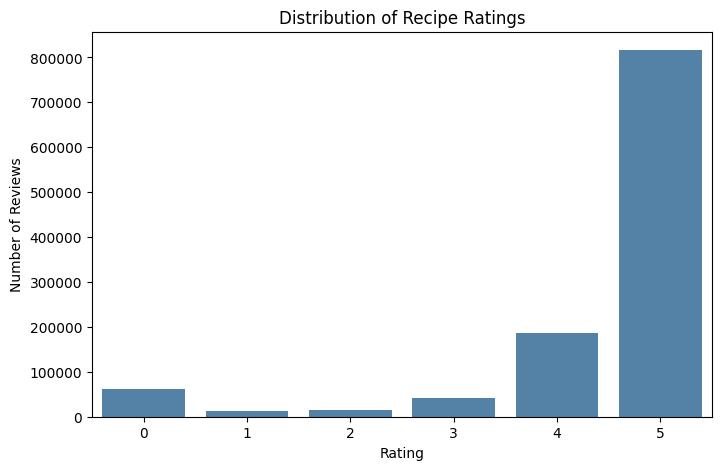

In [5]:
pd.set_option("display.float_format", "{:.2f}".format)
print("Rating statistics:")
display(interactions["rating"].describe())

print("Rating distribution:")
print(interactions["rating"].value_counts().sort_index())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=interactions,
    x="rating",
    color="steelblue"
)

plt.title("Distribution of Recipe Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()


## 8. User and Recipe Interaction Analysis

In [6]:

num_users = interactions["user_id"].nunique()
num_recipes = interactions["recipe_id"].nunique()
num_interactions = len(interactions)

print("Unique users:", num_users)
print("Unique rated recipes:", num_recipes)
print("Total interactions:", num_interactions)

# Reviews per user
ratings_per_user = interactions.groupby("user_id")["recipe_id"].nunique()

# Reviews per recipe
ratings_per_recipe = interactions.groupby("recipe_id")["user_id"].nunique()

print("\nRatings per user:")
display(ratings_per_user.describe())

print("\nRatings per recipe:")
display(ratings_per_recipe.describe())


Unique users: 226570
Unique rated recipes: 231637
Total interactions: 1132367

Ratings per user:


count   226570.00
mean         5.00
std         49.66
min          1.00
25%          1.00
50%          1.00
75%          2.00
max       7671.00
Name: recipe_id, dtype: float64


Ratings per recipe:


count   231637.00
mean         4.89
std         17.53
min          1.00
25%          1.00
50%          2.00
75%          4.00
max       1613.00
Name: user_id, dtype: float64

## 9. Dataset Merge and Feature Overview

In [7]:

merged = interactions.merge(
    recipes,
    left_on="recipe_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

print("Merged dataset shape:", merged.shape)

display(merged[
    [
        "user_id",
        "recipe_id",
        "name",
        "rating",
        "minutes",
        "ingredients",
        "n_ingredients"
    ]
].head())

print("Interactions without matching recipes:",
      merged["id"].isna().sum())


Merged dataset shape: (1132367, 17)


,user_id,recipe_id,name,rating,minutes,ingredients,n_ingredients
0,38094,40893,white bean green chile pepper soup,4,495,"['great northern beans', 'yellow onion', 'dice...",9
1,1293707,40893,white bean green chile pepper soup,5,495,"['great northern beans', 'yellow onion', 'dice...",9
2,8937,44394,devilicious cookie cake delights,4,20,"[""devil's food cake mix"", 'vegetable oil', 'eg...",4
3,126440,85009,baked potato toppings,5,10,"['mayonnaise', 'salsa', 'cheddar cheese', 'ref...",13
4,57222,85009,baked potato toppings,5,10,"['mayonnaise', 'salsa', 'cheddar cheese', 'ref...",13


Interactions without matching recipes: 0


## 10. Extended Exploratory Data Analysis

The following plots investigate recipe characteristics, user activity, recipe popularity, and rating patterns. The interaction data is large, so plots use summaries or samples where appropriate.

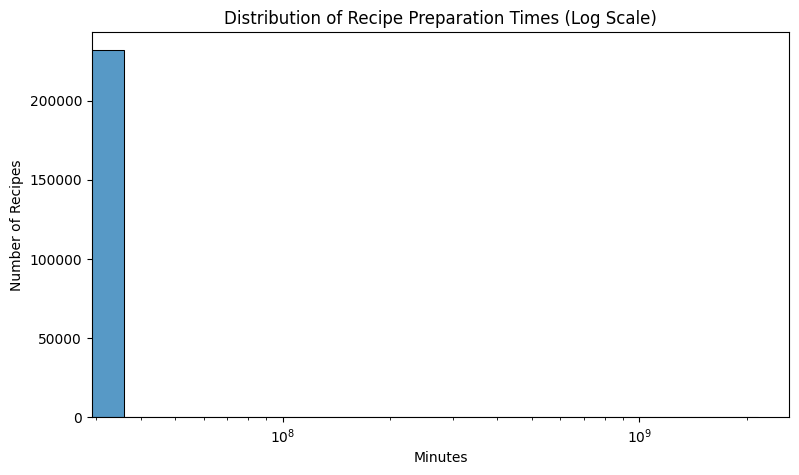

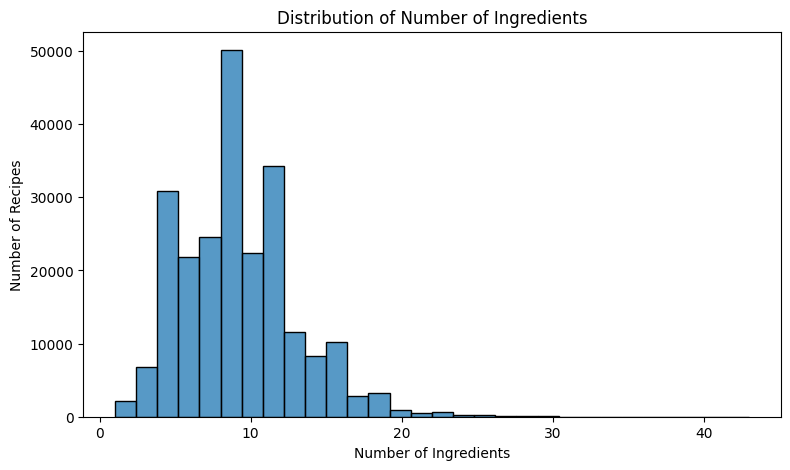

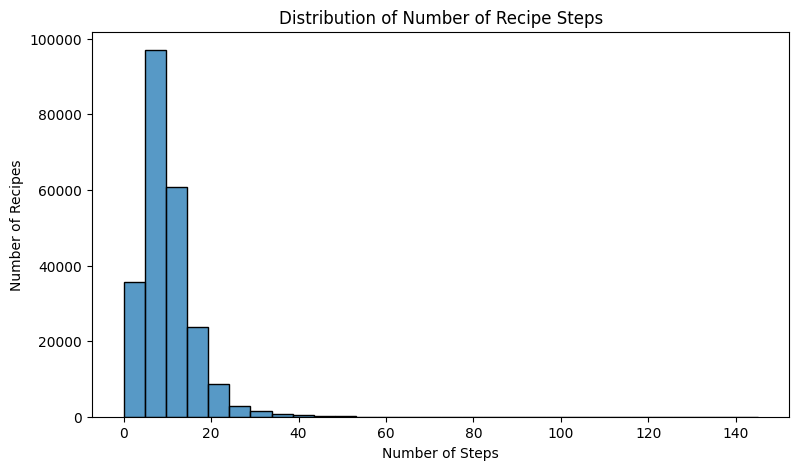

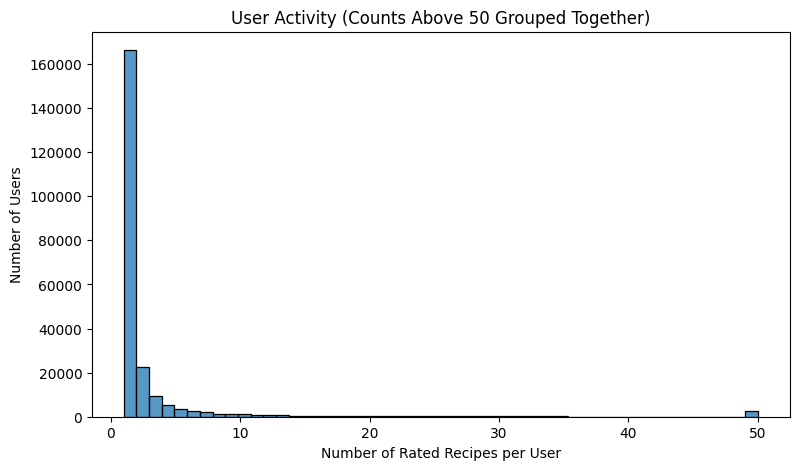

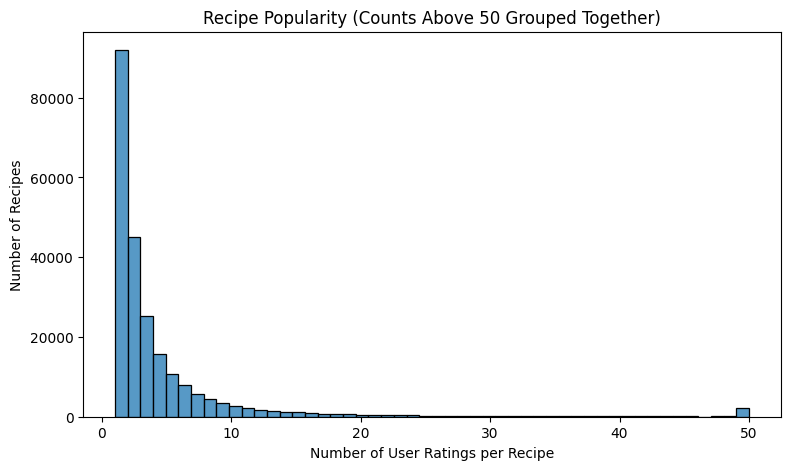

In [8]:
# Recipe preparation time is highly skewed, so use a log scale.
plt.figure(figsize=(9, 5))
sns.histplot(recipes.loc[recipes["minutes"] >= 0, "minutes"], bins=60)
plt.xscale("log")
plt.title("Distribution of Recipe Preparation Times (Log Scale)")
plt.xlabel("Minutes")
plt.ylabel("Number of Recipes")
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(recipes["n_ingredients"], bins=30)
plt.title("Distribution of Number of Ingredients")
plt.xlabel("Number of Ingredients")
plt.ylabel("Number of Recipes")
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(recipes["n_steps"], bins=30)
plt.title("Distribution of Number of Recipe Steps")
plt.xlabel("Number of Steps")
plt.ylabel("Number of Recipes")
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(ratings_per_user.clip(upper=50), bins=50)
plt.title("User Activity (Counts Above 50 Grouped Together)")
plt.xlabel("Number of Rated Recipes per User")
plt.ylabel("Number of Users")
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(ratings_per_recipe.clip(upper=50), bins=50)
plt.title("Recipe Popularity (Counts Above 50 Grouped Together)")
plt.xlabel("Number of User Ratings per Recipe")
plt.ylabel("Number of Recipes")
plt.show()

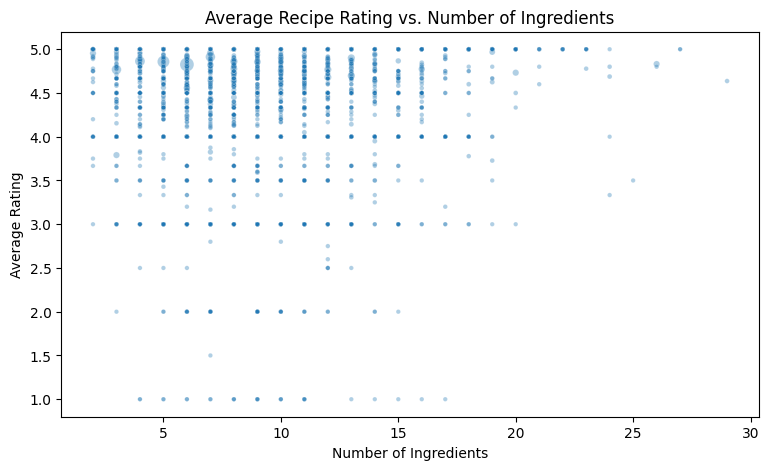

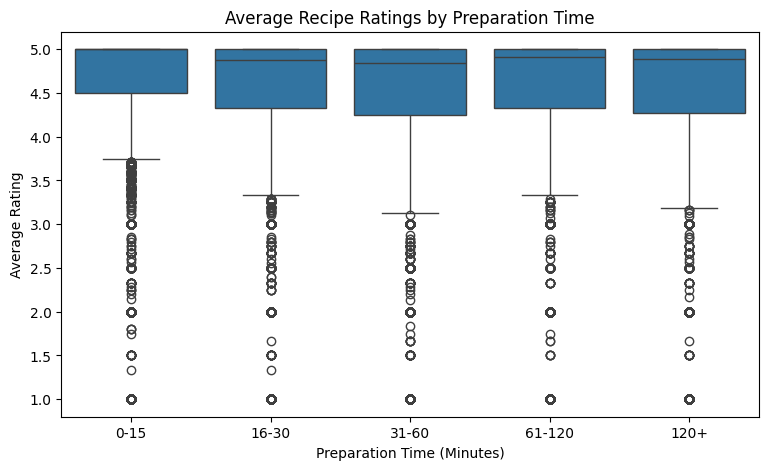

Percentage of interactions with a zero rating: 5.37 %
Percentage of interactions with a positive rating: 94.63 %


In [9]:
# Compare average ratings across groups of recipe characteristics.
recipe_rating_summary = merged.groupby("recipe_id").agg(
    average_rating=("rating", "mean"),
    rating_count=("rating", "size"),
    minutes=("minutes", "first"),
    n_ingredients=("n_ingredients", "first"),
    n_steps=("n_steps", "first")
).reset_index()

# Exclude zero ratings from this plot because their meaning needs separate investigation.
rated_recipe_summary = merged.loc[merged["rating"] > 0].groupby("recipe_id").agg(
    average_rating=("rating", "mean"),
    rating_count=("rating", "size"),
    minutes=("minutes", "first"),
    n_ingredients=("n_ingredients", "first"),
    n_steps=("n_steps", "first")
).reset_index()

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=rated_recipe_summary.sample(min(5000, len(rated_recipe_summary)), random_state=42),
    x="n_ingredients",
    y="average_rating",
    size="rating_count",
    sizes=(10, 100),
    alpha=0.35,
    legend=False
)
plt.title("Average Recipe Rating vs. Number of Ingredients")
plt.xlabel("Number of Ingredients")
plt.ylabel("Average Rating")
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=rated_recipe_summary.assign(
        time_group=pd.cut(
            rated_recipe_summary["minutes"],
            bins=[-1, 15, 30, 60, 120, np.inf],
            labels=["0-15", "16-30", "31-60", "61-120", "120+"]
        )
    ),
    x="time_group",
    y="average_rating"
)
plt.title("Average Recipe Ratings by Preparation Time")
plt.xlabel("Preparation Time (Minutes)")
plt.ylabel("Average Rating")
plt.show()

print("Percentage of interactions with a zero rating:",
      round((interactions["rating"].eq(0).mean()) * 100, 2), "%")
print("Percentage of interactions with a positive rating:",
      round((interactions["rating"].gt(0).mean()) * 100, 2), "%")

## 11. Data Preparation

For the first modeling pass, we will treat ratings from 1 through 5 as the target values. The 0 ratings will be counted and excluded from this initial rating-prediction experiment because they may indicate an interaction with no submitted rating. This assumption should be verified against the dataset documentation and discussed by the team.

Nutrition is stored as a list inside a text column. We will parse it into seven numerical features. We will also cap extreme preparation times at the 99th percentile to reduce the effect of unusually large values.

The first content-based models use recipe characteristics only. User/recipe average-rating baselines will separately test whether historical interaction information improves predictions.

In [10]:
import ast
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

model_data = merged.loc[merged["rating"].between(1, 5)].copy()

nutrition_names = [
    "calories", "total_fat", "sugar", "sodium",
    "protein", "saturated_fat", "carbohydrates"
]

def parse_nutrition(value):
    try:
        values = ast.literal_eval(value)
        if len(values) == 7:
            return pd.Series(values, index=nutrition_names)
    except (ValueError, SyntaxError, TypeError):
        pass
    return pd.Series([np.nan] * 7, index=nutrition_names)

nutrition_features = model_data["nutrition"].apply(parse_nutrition)
model_data = pd.concat([model_data, nutrition_features], axis=1)

feature_columns = [
    "minutes", "n_steps", "n_ingredients",
    "calories", "total_fat", "sugar", "sodium",
    "protein", "saturated_fat", "carbohydrates"
]

X = model_data[feature_columns].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())
X["minutes"] = X["minutes"].clip(upper=X["minutes"].quantile(0.99))
y = model_data["rating"]

X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split(
    X, y, model_data.index, test_size=0.2, random_state=42
)

train_interactions = model_data.loc[train_idx, ["user_id", "recipe_id", "rating"]].copy()
test_interactions = model_data.loc[test_idx, ["user_id", "recipe_id", "rating"]].copy()

print("Interactions used for modeling:", len(model_data))
print("Zero ratings excluded:", int(interactions["rating"].eq(0).sum()))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Number of recipe features:", len(feature_columns))

Interactions used for modeling: 1071520
Zero ratings excluded: 60847
Training rows: 857216
Testing rows: 214304
Number of recipe features: 10


## 12. Initial Models and Evaluation

We will begin with three types of comparisons:

- **Global mean baseline:** Predict the average training rating for every interaction.
- **Decision Tree and Random Forest:** Predict ratings from numerical recipe characteristics.
- **User/recipe mean baselines:** Use the average rating in the training set for that user or recipe. These are simple collaborative-filtering-style baselines.

All user and recipe averages are calculated from the training set only to avoid using test ratings when making predictions. Users or recipes not seen in training fall back to the global training average.

In [11]:
def calculate_metrics(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5
    }

results = []

global_mean = y_train.mean()
global_predictions = np.full(len(y_test), global_mean)
results.append(calculate_metrics("Global Mean", y_test, global_predictions))

decision_tree = DecisionTreeRegressor(
    max_depth=12,
    min_samples_leaf=20,
    random_state=42
)
decision_tree.fit(X_train, y_train)
tree_predictions = decision_tree.predict(X_test)
results.append(calculate_metrics("Decision Tree", y_test, tree_predictions))

random_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=16,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)
random_forest.fit(X_train, y_train)
forest_predictions = random_forest.predict(X_test)
results.append(calculate_metrics("Random Forest", y_test, forest_predictions))

user_means = train_interactions.groupby("user_id")["rating"].mean()
recipe_means = train_interactions.groupby("recipe_id")["rating"].mean()

user_predictions = test_interactions["user_id"].map(user_means).fillna(global_mean)
recipe_predictions = test_interactions["recipe_id"].map(recipe_means).fillna(global_mean)

results.append(calculate_metrics("User Mean", y_test, user_predictions))
results.append(calculate_metrics("Recipe Mean", y_test, recipe_predictions))

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df)

,Model,MAE,RMSE
2,Random Forest,0.50,0.71
3,User Mean,0.44,0.71
1,Decision Tree,0.51,0.72
0,Global Mean,0.52,0.72
4,Recipe Mean,0.47,0.76


,Model,Training MAE,Testing MAE,Training RMSE,Testing RMSE
0,Decision Tree,0.50,0.51,0.71,0.72
1,Random Forest,0.49,0.50,0.69,0.71


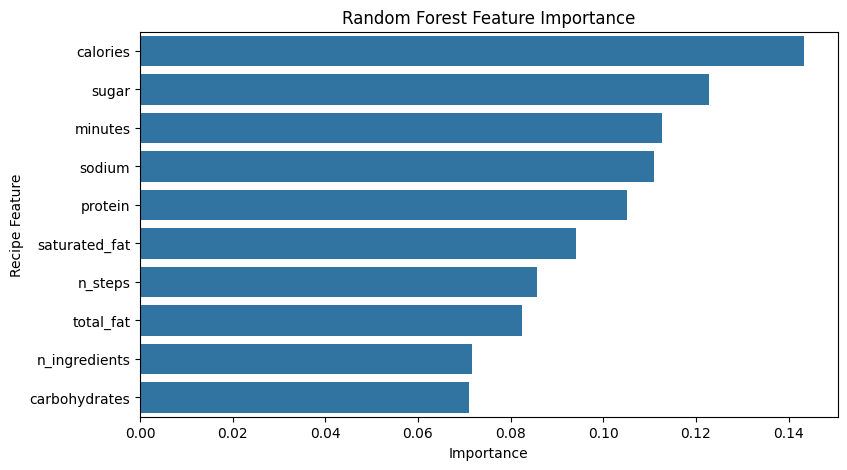

In [12]:
# Compare training and testing errors to get an initial indication of overfitting.
fit_results = []

for name, model in [
    ("Decision Tree", decision_tree),
    ("Random Forest", random_forest)
]:
    fit_results.append({
        "Model": name,
        "Training MAE": mean_absolute_error(y_train, model.predict(X_train)),
        "Testing MAE": mean_absolute_error(y_test, model.predict(X_test)),
        "Training RMSE": mean_squared_error(y_train, model.predict(X_train)) ** 0.5,
        "Testing RMSE": mean_squared_error(y_test, model.predict(X_test)) ** 0.5
    })

fit_comparison = pd.DataFrame(fit_results)
display(fit_comparison)

feature_importance = pd.Series(
    random_forest.feature_importances_,
    index=feature_columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=feature_importance.values, y=feature_importance.index)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Recipe Feature")
plt.show()

## 13. Initial Interpretation and Limitations

The User Mean model performed best with an MAE of 0.44, compared to 0.52 for the Global Mean. The Decision Tree and Random Forest performed slightly worse, suggesting recipe characteristics alone aren't enough to accurately predict ratings. Training and testing errors were very similar, showing no obvious overfitting.

Our next steps are to implement different models. Testing more strategies to see which is more accurate

## 14. Remaining Work Plan and Timeline

| Stage | Tasks |
|---|---|
| After Thanksgiving | Implement collaborative filtering and compare it with existing models |
| Following work session | Explore hybrid recommendation models and tune model parameters |
| Final project preparation | Evaluate results, compare model performance, and complete the final report and presentation |

**Remaining tasks**
1. Implement additional recommendation models, particularly collaborative filtering.
2. Explore combining content-based and collaborative filtering approaches.
3. Compare model performance using MAE and RMSE.
4. Evaluate results and finalize the project report and presentation.